# The paper's own protocol: the Table 5 fit judged in sample, against the same ten surveys held out

**Question:** What does the in-sample protocol of the source paper, a fit judged on the same ten surveys it was fitted to, say about the HP500 model, and what changes when each survey is held out instead?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say what the published method for this crusher is, and what protocol it uses to judge its own model;
- run that protocol on the ten surveys, fitting the physics, the bounded residual and an unconstrained regression on all ten rows with CrusherCal's public functions;
- read each fitted coefficient for its physical sense, and say why a good in-sample number cannot decide between the models;
- set the in-sample errors beside the held-out errors of the same models on both targets, and read the optimism.

## Setup

Numpy and matplotlib. The CrusherCal functions come from the pipeline's `hp500` folder, which needs only numpy.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports the survey reader, the engine, the backbone builder and the CrusherCal module, whose public functions fit the models.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import HP500_QREF, bond_power, calibrated_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
from pipeline.hp500 import backbone, loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, and `VERSION`, the release label that the backbone document carries. The two measured targets are the throughput in t/h and the power in kW.

The cell reads the table and the release label and keeps the two measured targets and the two regressors of the free-form model.

In [2]:
# Read the survey table and the release label; keep the two measured targets and the regressors
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
targets = {"tph": measured_q, "kW": measured_kw}
print("surveys:", len(surveys), "| release label:", version)

surveys: 10 | release label: 0.11.000


## Method

**The product's side: the calibrated backbone.** The backbone is the engine's calibrated lane with its published constants: the capacity base $Q_T \approx 647$ t/h and the power form $P_c = 1.30\,P_d + 110$ kW (Rocha et al., 2024; https://doi.org/10.3390/min14090919), where $P_d$ is the engine's Bond power. CrusherCal turns each of these constants into a scalar that can be refitted to whichever rows it is given. The cell runs the engine at the ten surveys and prints the two inputs, the capacity factor and the Bond power, as in notebook 02.

In [3]:
# The inputs of the two backbones, to 0.01 as the committed documents carry them: capacity factor, Bond power
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]).round(2) / HP500_QREF
bond_kw = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs]).round(2)
print("capacity factor by survey:", shape.round(3))
print("Bond power by survey [kW]:", bond_kw.round(1))

capacity factor by survey: [1.868 1.868 1.711 1.711 1.711 1.5   1.447 1.605 1.5   1.895]
Bond power by survey [kW]: [229.5 233.7 224.9 225.7 234.8 222.5 196.1 212.7 221.6 237.5]


## Comparison

**The source.** The published method for this machine is Rocha, Campos, Silva and Tavares (2024; https://doi.org/10.3390/min14090919): a fit-for-purpose model of the HP500, with the Andersen-Whiten classification and breakage parameters, the capacity and the power, fitted to the ten surveys and judged on them. Its protocol is the usual one for such models, an in-sample fit: the constants come from the ten surveys, and the model's agreement with the same ten surveys is the evidence. The neighbouring literature on learned surrogates of comminution models has the same shape: Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) judge a network against the model it emulates, not against a held-out plant.

**The protocol, step 1: fit the physics on all ten rows.** The in-sample protocol uses every survey to fit and then judges on the same surveys. In CrusherCal this is the leaky variant of the fold, `fold_indices(10, i, leaky=True)`, whose training rows are all ten. The cell fits the capacity base with `fit_capacity_base` (a least-squares scalar, $Q_T = \sum s\,m / \sum s^2$) and the power form with `fit_power_form` (the pair $\zeta$, $P_n$ by ordinary least squares), and prints them beside the published constants.

In [4]:
# Fit the physics on all ten surveys, the protocol of the paper: one capacity base, one power form
everyone = loo.fold_indices(10, 0, leaky=True)
qt = loo.fit_capacity_base(shape, measured_q, everyone)
zeta, pn = loo.fit_power_form(bond_kw, measured_kw, everyone)
print("rows fitted:", everyone.tolist())
print(f"capacity base: refitted {qt:.1f} t/h | the paper's {HP500_QREF} t/h")
print(f"power form Pc = zeta Pd + Pn: zeta = {zeta:.4f}, Pn = {pn:.1f} kW | the paper's 1.30 and 110 kW")

rows fitted: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
capacity base: refitted 686.0 t/h | the paper's 647 t/h
power form Pc = zeta Pd + Pn: zeta = -2.4146, Pn = 828.6 kW | the paper's 1.30 and 110 kW


The refitted capacity base is 686.0 t/h, 6 percent above the paper's 647 t/h, a small and physical move of one number. The power form is another matter: the in-sample optimum is $\zeta = -2.4146$ with $P_n = 828.6$ kW, a line of negative slope in which more Bond power predicts less measured power, and a negative efficiency has no physical meaning. It arises because the Bond power varies little (196 to 238 kW, notebook 02) against a measured power that spans 187 to 355 kW and is negatively correlated with it, so the regression tilts its line downward to follow the survey-to-survey variation: it is fitting the spread, not the physics. The second figure of this notebook draws that line.

**The protocol, step 2: the free-form regression and the residual model.** The other two models of CrusherCal are fitted on the same ten rows. M2 is an ordinary least-squares plane in the setting and the f80 (`fit_freeform`), three coefficients per target and no physics. M1 adds to the backbone a ridge residual (`fit_residual`, penalty 1, clipped to 20 percent of the backbone), whose coefficients are on standardized features. The cell prints the coefficients of both, and stores the in-sample predictions of the four models: the backbone M0, M1, M2 and the constant mean.

In [5]:
# The four models fitted on all ten rows, and their in-sample predictions for both targets
fitted = {("tph", "M0"): qt * shape, ("kW", "M0"): zeta * bond_kw + pn}
for key, y in targets.items():
    plane = loo.fit_freeform(features, y, everyone)
    fitted[key, "M2"] = np.array([loo.predict_freeform(plane, x) for x in features])
    fitted[key, "mean"] = np.full(10, y.mean())
    fits = [loo.fit_residual(features, fitted[key, "M0"], y, everyone, i) for i in range(10)]
    fitted[key, "M1"] = fitted[key, "M0"] + np.array([f.clipped for f in fits])
    print(key, "M2 coefficients (intercept, setting, f80):", np.round(plane, 2))
    print(key, "M1 ridge coefficients (intercept, setting, f80):", np.round(fits[0].coef, 1))

tph M2 coefficients (intercept, setting, f80): [-802.3    36.56    2.68]
tph M1 ridge coefficients (intercept, setting, f80): [-7.7 95.7 56.7]
kW M2 coefficients (intercept, setting, f80): [ 7.7653e+02 -9.4200e+00 -5.3000e-01]
kW M1 ridge coefficients (intercept, setting, f80): [  0.  -34.8 -24.1]


The free-form regression has three coefficients per target, against the one scalar of the throughput backbone, and the setting coefficient of its throughput plane, +36.6 t/h per millimetre of setting, is the only one of them that reads as physics. The power plane has a negative setting coefficient, -9.42 kW per millimetre, which is what the measured power does as the setting opens. These coefficients are what the in-sample protocol is free to bend towards the ten points, and the next cell counts what that buys.

**The protocol, step 3: judge in sample.** The error of each model on the surveys it was fitted to, as the paper reports it, with `loo.mape`. Two reference rows come with them: the backbone as shipped, whose constants are the paper's 647 t/h and 1.30, 110 kW and were not refitted by this notebook, and the bare Bond power for the power target.

In [6]:
# In-sample MAPE of the four models, and of the backbone as shipped with the paper's constants
shipped = {"tph": np.array([r.throughput_tph for r in runs]),
           "kW": np.array([calibrated_power(v) for v in bond_kw])}
models = ("M0", "M1", "M2", "mean")
in_sample = {(key, m): loo.mape(y, fitted[key, m]) for key, y in targets.items() for m in models}
for key, y in targets.items():
    print(key, {m: round(in_sample[key, m], 2) for m in models})
    print(f"     shipped constants {loo.mape(y, shipped[key]):6.2f} %")
print("     bare Bond power on the power target:", round(loo.mape(measured_kw, bond_kw), 2), "%")

tph {'M0': 10.95, 'M1': 8.51, 'M2': 8.24, 'mean': 16.46}
     shipped constants  11.55 %
kW {'M0': 19.28, 'M1': 12.0, 'M2': 9.46, 'mean': 22.03}
     shipped constants  47.58 %
     bare Bond power on the power target: 26.88 %


An in-sample fit is not wrong; it answers a different question than "how will it do on the next survey". The previous cells ran that protocol with the pipeline's public functions, and the in-sample row of each model above is the evidence the paper would report. The cell below runs the product's protocol on the same rows, CrusherCal's `loo.build`, which refits every scalar without the held-out survey in each of the ten folds, and sets the two kinds of error side by side. This is the one place in the topic where the in-sample and held-out errors are tabulated together; notebooks 01, 02 and 04 compute what each adds.

In [7]:
# The product's protocol on the same rows: CrusherCal's held-out run, and the table of the two kinds of error
names = {"M0": "M0_backbone", "M1": "M1_residual", "M2": "M2_freeform", "mean": "constant_mean"}
doc = loo.build(backbone.build(surveys, version), version)
held_out = {(key, m): doc["loo"][key]["strict"][names[m]]["mape_pct"] for key in targets for m in models}
print("target  model  in sample  held out  optimism")
for key in targets:
    for m in models:
        a, b = in_sample[key, m], held_out[key, m]
        print(f"{key:6s} {m:6s} {a:8.2f} % {b:8.2f} % {b - a:+8.2f}")

target  model  in sample  held out  optimism
tph    M0        10.95 %    12.09 %    +1.14
tph    M1         8.51 %    13.45 %    +4.94
tph    M2         8.24 %    12.18 %    +3.94
tph    mean      16.46 %    18.29 %    +1.83
kW     M0        19.28 %    25.94 %    +6.66
kW     M1        12.00 %    25.37 %   +13.37
kW     M2         9.46 %    14.03 %    +4.57
kW     mean      22.03 %    24.48 %    +2.45


The figure draws the table: for each target, the in-sample error and the held-out error of the four models, side by side.

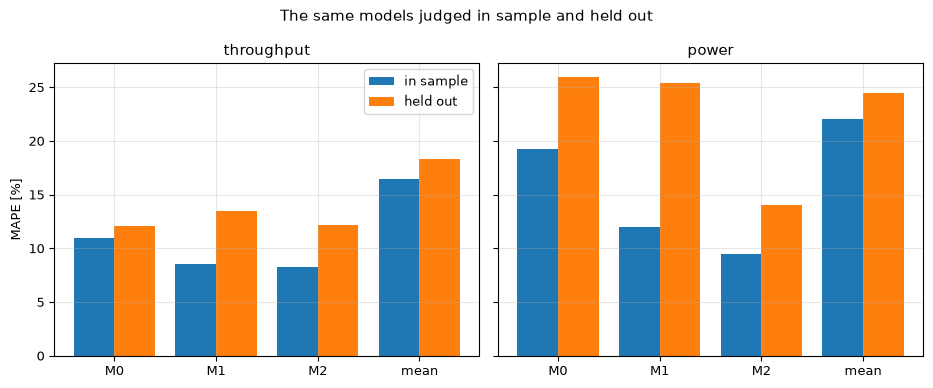

In [8]:
# Bars of the in-sample and held-out error of the four models, one panel per target
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
x = np.arange(len(models))
for ax, key, label in zip(axes, targets, ("throughput", "power")):
    ax.bar(x - 0.2, [in_sample[key, m] for m in models], 0.4, label="in sample")
    ax.bar(x + 0.2, [held_out[key, m] for m in models], 0.4, label="held out")
    ax.set_xticks(x, ["M0", "M1", "M2", "mean"])
    ax.set_title(label)
axes[0].set_ylabel("MAPE [%]")
axes[0].legend()
fig.suptitle("The same models judged in sample and held out")
fig.tight_layout()
plt.show()

Read as the paper reads it, the in-sample half of the story is favourable: on the throughput the shipped backbone, at 11.55 percent, and the refitted M0, at 10.95, beat the constant mean at 16.46, and on the power the refitted form, at 19.28 percent, beats the mean at 22.03 and the bare Bond power at 26.88. But the models that win in sample are the ones with freedom beyond the physics. The two that carry fitted coefficients beyond the refitted physics, M1 and M2, beat M0 in sample: 8.51 and 8.24 percent against 10.95 on the throughput, and 12.00 and 9.46 against 19.28 on the power (the constant mean, which knows nothing about the setting, is the worst bar). The number of free parameters does not order them: M1 is M0 plus a ridge residual with three coefficients, so it carries more nominal parameters than the three-coefficient plane M2, yet its in-sample error is the higher of the two; its ridge penalty and its 20 percent clip shrink its effective parameters, which is why a count of coefficients is a poor guide. Held out, the advantage depends on the target. On the throughput it disappears: M0 is the best at 12.09 percent, M2 at 12.18 and M1 at 13.45 are behind it, and M1 loses 4.94 points to the hold-out against 1.14 for M0. On the power it splits: the free-form plane M2 keeps its advantage and is the best held-out model, at 14.03 percent against 25.94 for M0, while M1 falls to 25.37; and the refitted form, better than the mean in sample (19.28 against 22.03), is worse than it held out (25.94 against 24.48), so the in-sample protocol reports a power skill that does not exist. The figure cannot say how many surveys it would take to make the in-sample number honest, only that with ten and a flat regressor it is not.

The second figure plots the measured power against the Bond power, with the in-sample line of the refitted form and the line of the paper's constants.

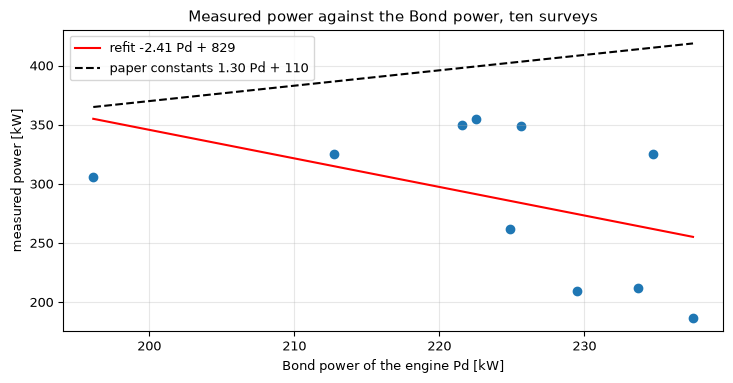

correlation of the measured power with the Bond power: -0.453


In [9]:
# Scatter of the measured power against the Bond power, with the in-sample refit line and the paper's constants
fig, ax = plt.subplots()
ax.scatter(bond_kw, measured_kw)
line = np.linspace(bond_kw.min(), bond_kw.max(), 20)
ax.plot(line, zeta * line + pn, "r-", label=f"refit {zeta:.2f} Pd + {pn:.0f}")
ax.plot(line, 1.30 * line + 110, "k--", label="paper constants 1.30 Pd + 110")
ax.set_xlabel("Bond power of the engine Pd [kW]")
ax.set_ylabel("measured power [kW]")
ax.set_title("Measured power against the Bond power, ten surveys")
ax.legend()
fig.tight_layout()
plt.show()
corr = np.corrcoef(bond_kw, measured_kw)[0, 1]
print("correlation of the measured power with the Bond power:", round(float(corr), 3))

The ten points form a cloud without a clean relation: the red line tilts down through them, the black dashed line of the paper's constants lies above all of them, and the correlation printed under the figure is negative. The figure shows why an in-sample fit cannot be trusted to carry physical meaning on ten points and a flat regressor, and why the product's report keeps the measured power as the reference and does not offer the model kW as a prediction. It does not show what happens on a survey outside the ten; that is what the held-out bars of the first figure measure, and the power bars say that the answer is not good.

## Results

**Answer:** the in-sample protocol is favourable to the HP500 model and cannot tell it apart from an overfit. On throughput the in-sample errors are 11.55 percent for the shipped backbone, 10.95 for the refitted scalar, 8.51 for the bounded residual, 8.24 for the free-form regression and 16.46 for the constant mean, and the two models with free coefficients beyond the physics, M1 and M2, beat the refitted scalar in sample and lose that advantage held out. On power the in-sample refit of the paper's form gives 19.28 percent, better than the paper's constants (47.58 percent) and the bare Bond power (26.88 percent), with a negative coefficient, zeta = -2.4146, that has no physical meaning. Held out, the same models score 12.09 (M0), 13.45 (M1), 12.18 (M2) and 18.29 (mean) on the throughput, so M1 loses 4.94 points to the hold-out and M0 1.14, and 25.94, 25.37, 14.03 and 24.48 on the power, so the refitted form goes from beating the mean in sample to losing to it, while the free-form plane M2 keeps its advantage held out and is the best power model at 14.03.

The first figure shows the optimism as the gap between the paired bars, the second the absurd coefficient on a cloud with no relation. A validator would conclude that the paper's protocol is sound for what it claims, a calibration, and silent on what the product wants to claim, a prediction; that the physics-free regression winning the power in sample and the sign of zeta are the evidence that the protocol cannot discriminate between models; and that holding each survey out in turn, with the same code, is the next step, which notebook 04 measures as the product's claim.

## Summary

The published method for this crusher fits ten surveys and judges the fit on the same ten, a protocol that favours whichever model has more freedom: here the physics-free regression and a power coefficient with the wrong sign. Run with CrusherCal's public functions, the same models held out give the optimism per model and target in one table, and the power form that beat the constant mean in sample loses to it held out. The product's own claim, measured on this basis, is the subject of notebook 04.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026